In [1]:
import pandas as pd
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

In [2]:
URL = "http://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

outer = ZipFile(BytesIO(urlopen(URL).read()))
inner = ZipFile(BytesIO(outer.read("bank-additional.zip")))
df = pd.read_csv(inner.open("bank-additional/bank-additional.csv"), sep=";")
print(df.shape)

(4119, 21)


In [3]:
df = df.drop(columns=["duration"])

In [4]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["y"])
y = df["y"]

y = y.map({"no": 0, "yes": 1})
X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [5]:
from catboost import CatBoostClassifier

model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    eval_metric="AUC",
    random_seed=42,
    verbose=200,
)

In [6]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)


def metrics(X_test, y_test, model):
    y_pred = model.predict(X_test)
    y_probs = model.predict_proba(X_test)[:, 1]

    result = {
        "Accuracy": round(accuracy_score(y_test, y_pred), 2),
        "Precision": round(precision_score(y_test, y_pred), 2),
        "Recall": round(recall_score(y_test, y_pred), 2),
        "F1 Score": round(f1_score(y_test, y_pred), 2),
        "ROC AUC": round(roc_auc_score(y_test, y_probs), 2),
    }

    return pd.DataFrame(result, index=[0])

In [7]:
model.fit(X_train, y_train)

metrics(X_test, y_test, model)

0:	total: 59.6ms	remaining: 59.5s
200:	total: 312ms	remaining: 1.24s
400:	total: 564ms	remaining: 842ms
600:	total: 814ms	remaining: 541ms
800:	total: 1.06s	remaining: 264ms
999:	total: 1.31s	remaining: 0us


,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,0.89,0.53,0.2,0.29,0.72


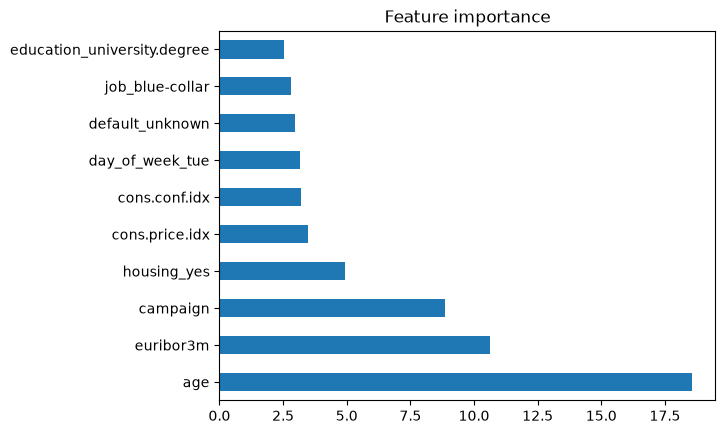

In [10]:
import matplotlib.pyplot as plt

imp = (
    pd.Series(model.get_feature_importance(), index=X_train.columns)
    .sort_values(ascending=False)
    .head(10)
)

imp.plot.barh()
plt.title("Feature importance")
plt.show()